# [GSE167324](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE167324)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-09-20
> - Modified: 2024-09-20

# 1. Experimental Design

> Analysis of the eIF4E3-dependent translatome after Torin1-induced stress in N2a cells ctrl and eIF4E3 KO.
> - Benjamin Weiss, George Edward Allen, Joachim Kloehn, Karim Abid, Pascale Jaquier-Gubler, Joseph Alphonsus Curran, eIF4E3 forms an active eIF4F complex during stresses (eIF4FS) targeting mTOR and re-programs the translatome, Nucleic Acids Research, Volume 49, Issue 9, 21 May 2021, Pages 5159–5176, https://doi.org/10.1093/nar/gkab267.
> - total RNA-seq: TruSeq stranded RNA Library Prep, Illumina
> - Ribo-seq: RiboMinus v2 Eukaryote Kit, Invitrogen
> - Illumina HiSeq 4000, PE150
> - mm10

| Sample | Cell | Organism | Source | Strand | Genotype | Treatment | Time | Fraction | Replicate |
| - | - | - | - | - | - | - | - | - | - |
| WT DMSO | N2a | Mus musculus | Neuroblastoma cell line | Neuro-2a | eIF4E3 WT | DMSO | 2h | Total RNA, Ribosome RNA | rep1~3 |
| WT Torin1 | N2a | Mus musculus | Neuroblastoma cell line | Neuro-2a | eIF4E3 WT | Torin1 | 2h | Total RNA, Ribosome RNA | rep1~3 |
| KO DMSO | N2a | Mus musculus | Neuroblastoma cell line | Neuro-2a | eIF4E3 KO | DMSO | 2h | Total RNA, Ribosome RNA | rep1~3 |
| KO Torin1 | N2a | Mus musculus | Neuroblastoma cell line | Neuro-2a | eIF4E3 KO | Torin1 | 2h | Total RNA, Ribosome RNA | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/riboseq_Mm_N2a_eIF4E3_GSE167324"

In [3]:
raw_counts_ribo <- file.path(
    data_dir, "02_output_riboseq", "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts_ribo) <- colnames(raw_counts_ribo) |> 
    sub("^02_output_riboseq/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts_ribo)

[1] 22431    20

In [4]:
coldata_ribo <- colnames(raw_counts_ribo) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("N2a"))) |>
    separate(
        col = sample, into = c(
            "Cell", "Gene", "Group", "Treatment", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Treatment = factor(Treatment, levels = c("DMSO", "Torin1")),
        Fraction = recode(Fraction, "total" = "Total", "ribo" = "Ribosome") |>
            factor(levels = c("Total", "Ribosome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Treatment, Fraction, Replicate) |>
    column_to_rownames("sample")

coldata_ribo

,Cell,Gene,Group,Treatment,Fraction,Replicate
,<chr>,<chr>,<fct>,<fct>,<fct>,<fct>
WT_DMSO_ribo_rep1,N2a,eIF4E3,WT,DMSO,Ribosome,rep1
WT_DMSO_ribo_rep2,N2a,eIF4E3,WT,DMSO,Ribosome,rep2
WT_DMSO_ribo_rep3,N2a,eIF4E3,WT,DMSO,Ribosome,rep3
WT_Torin1_ribo_rep1,N2a,eIF4E3,WT,Torin1,Ribosome,rep1
WT_Torin1_ribo_rep2,N2a,eIF4E3,WT,Torin1,Ribosome,rep2
WT_Torin1_ribo_rep3,N2a,eIF4E3,WT,Torin1,Ribosome,rep3
KO_DMSO_ribo_rep1,N2a,eIF4E3,KO,DMSO,Ribosome,rep1
KO_DMSO_ribo_rep2,N2a,eIF4E3,KO,DMSO,Ribosome,rep2
KO_DMSO_ribo_rep3,N2a,eIF4E3,KO,DMSO,Ribosome,rep3


In [5]:
# Function
process_omics_data <- function(
    file_path, align_pattern = NULL, sample_pattern = NULL, prefix_pattern = NULL) {
    
    raw_df <- read.table(file_path, header = TRUE, sep = "\t", check.names = FALSE)
    
    colnames(raw_df) <- colnames(raw_df) |> 
        sub(pattern = align_pattern, replacement = "\\1", x = _) |> 
        gsub(pattern = "-", replacement = "_")
        
    sample_cols <- colnames(raw_df)[
        str_detect(colnames(raw_df), fixed(sample_pattern))]

    col_data <- tibble(sample = sample_cols) |> 
    separate(
        col = sample, into = c(
            "Cell", "Gene", "Group", "Treatment", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub(prefix_pattern, "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Treatment = factor(Treatment, levels = c("DMSO", "Torin1")),
        Fraction = recode(Fraction, "total" = "Total", "ribo" = "Ribosome") |>
            factor(levels = c("Total", "Ribosome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Treatment, Fraction, Replicate)

    count_matrix <- raw_df |> 
        column_to_rownames("Geneid") |> 
        rename_with(~ sub(prefix_pattern, "", .x)) |>
        select(all_of(col_data$sample)) |> 
        as.matrix()
    
    col_data <- column_to_rownames(col_data, "sample")
    
    return(list(counts = count_matrix, coldata = col_data, raw = raw_df))
}

In [6]:
ribo_res <- process_omics_data(
    file_path = file.path(
        data_dir, "02_output_riboseq", "04_counts", "featureCounts.tsv"),
    align_pattern = "^02_output_riboseq/03_align/(.*?).Aligned.out.bam",
    sample_pattern = "N2a" ,prefix_pattern = "^[^_]+_[^_]+_")

rna_res <- process_omics_data(
    file_path = file.path(
        data_dir, "04_output_rnaseq", "04_counts", "featureCounts.tsv"),
    align_pattern = "^04_output_rnaseq/03_align/(.*?).Aligned.out.bam",
    sample_pattern = "N2a" ,prefix_pattern = "^[^_]+_[^_]+_")

In [7]:
common_genes <- intersect(rownames(rna_res$counts), rownames(ribo_res$counts))

counts_rna_shared  <- rna_res$counts[common_genes, , drop = FALSE]
counts_ribo_shared <- ribo_res$counts[common_genes, , drop = FALSE]

raw_counts <- cbind(counts_rna_shared, counts_ribo_shared)
coldata    <- rbind(rna_res$coldata, ribo_res$coldata)

In [8]:
anno_gene <- rna_res$raw |> 
    filter(Geneid %in% common_genes) |> 
    select(Geneid, symbol = gene_name, type = gene_type, basepairs = Length) |> 
    arrange(match(Geneid, common_genes)) |> 
    column_to_rownames("Geneid") |> 
    DataFrame()

## 2). Object Construction

In [9]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 22431 24 
metadata(0):
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(24): WT_DMSO_total_rep1 WT_DMSO_total_rep2 ...
  KO_Torin1_ribo_rep2 KO_Torin1_ribo_rep3
colData names(6): Cell Gene ... Fraction Replicate

In [10]:
# Three-way Factorial Design
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Treatment * Fraction)

dds

class: DESeqDataSet 
dim: 22431 24 
metadata(1): version
assays(1): counts
rownames(22431): ENSMUSG00000051951.5 ENSMUSG00000025900.12 ...
  ENSMUSG00000064368.1 ENSMUSG00000064370.1
rowData names(3): symbol type basepairs
colnames(24): WT_DMSO_total_rep1 WT_DMSO_total_rep2 ...
  KO_Torin1_ribo_rep2 KO_Torin1_ribo_rep3
colData names(6): Cell Gene ... Fraction Replicate

In [11]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [12]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 12000 
 Remove: 10431 
 Retention rate: 53.5 %


In [13]:
design <- model.matrix(~ Group * Treatment * Fraction, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 11973 
 Remove: 10458 
 Retention rate: 53.38 %


# 3. Normalization

In [14]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [15]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor 
# using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [16]:
# Calculation of cpm expression matrix adjusted by normalization factor 
# using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [17]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [18]:
rld <- rlog(dds, blind = FALSE)

In [19]:
suppressPackageStartupMessages(library(vsn))

In [20]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [21]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


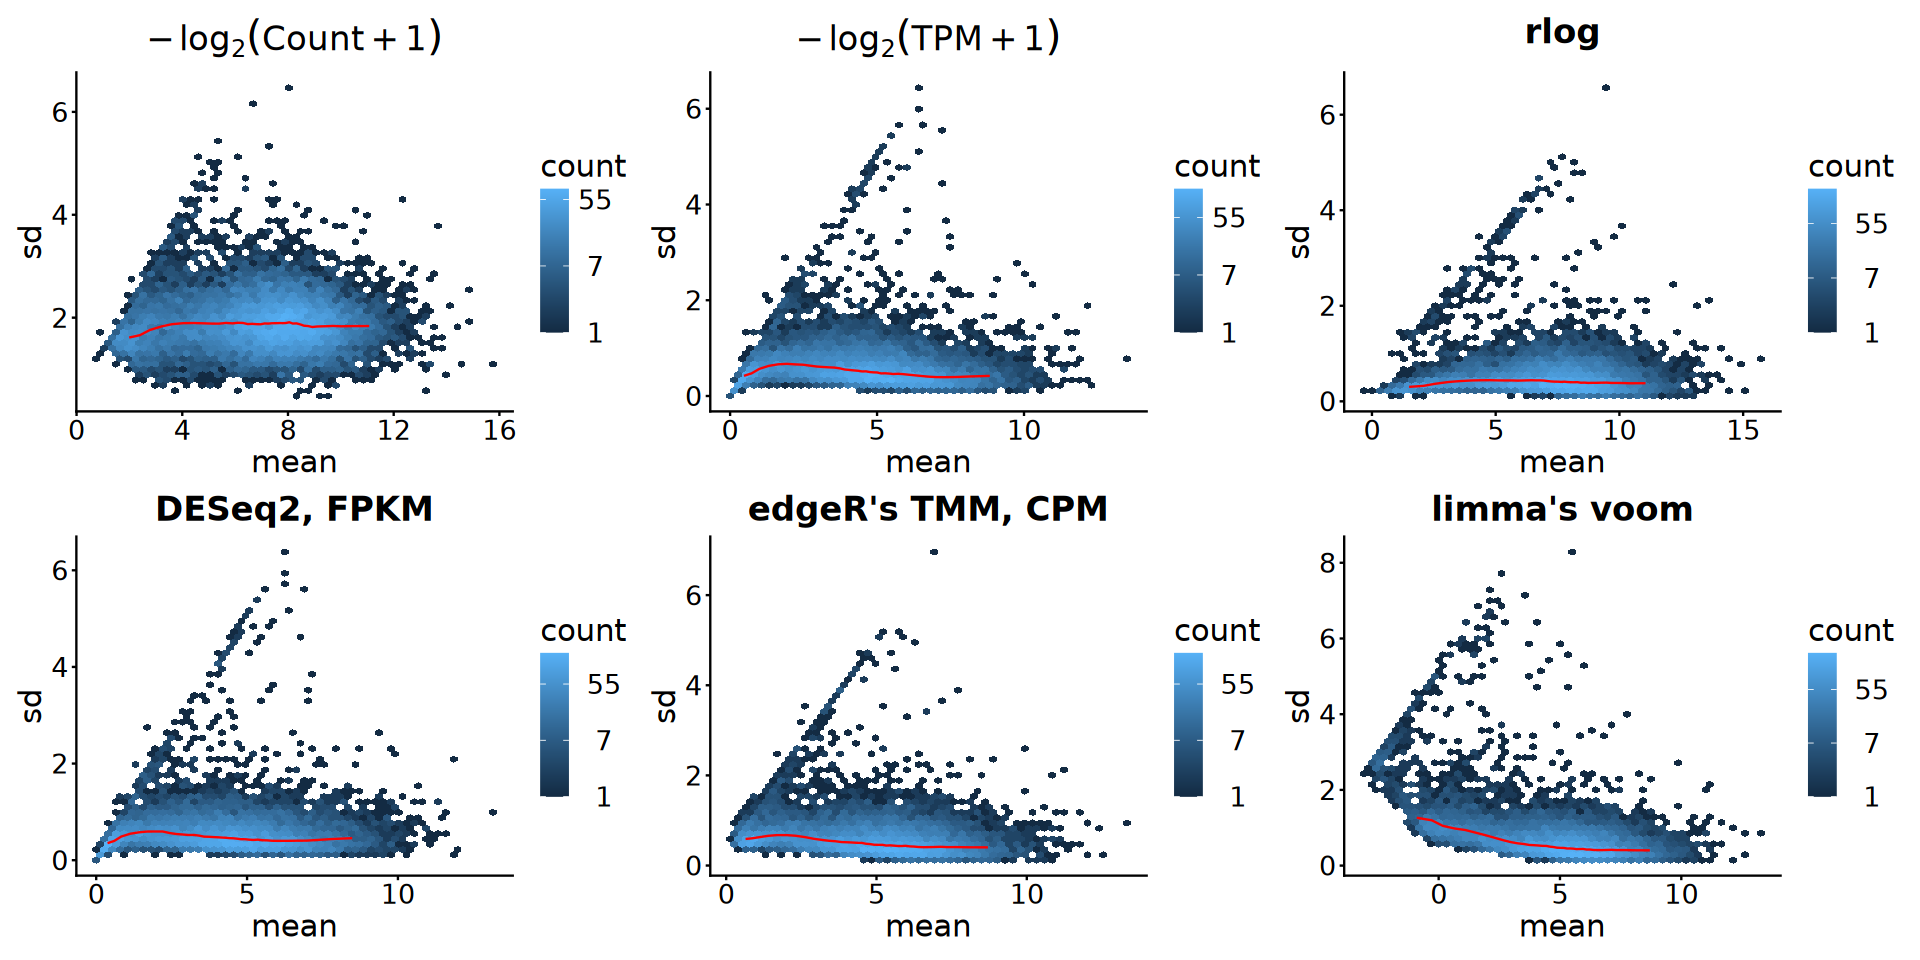

In [22]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [23]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [24]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Fraction, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

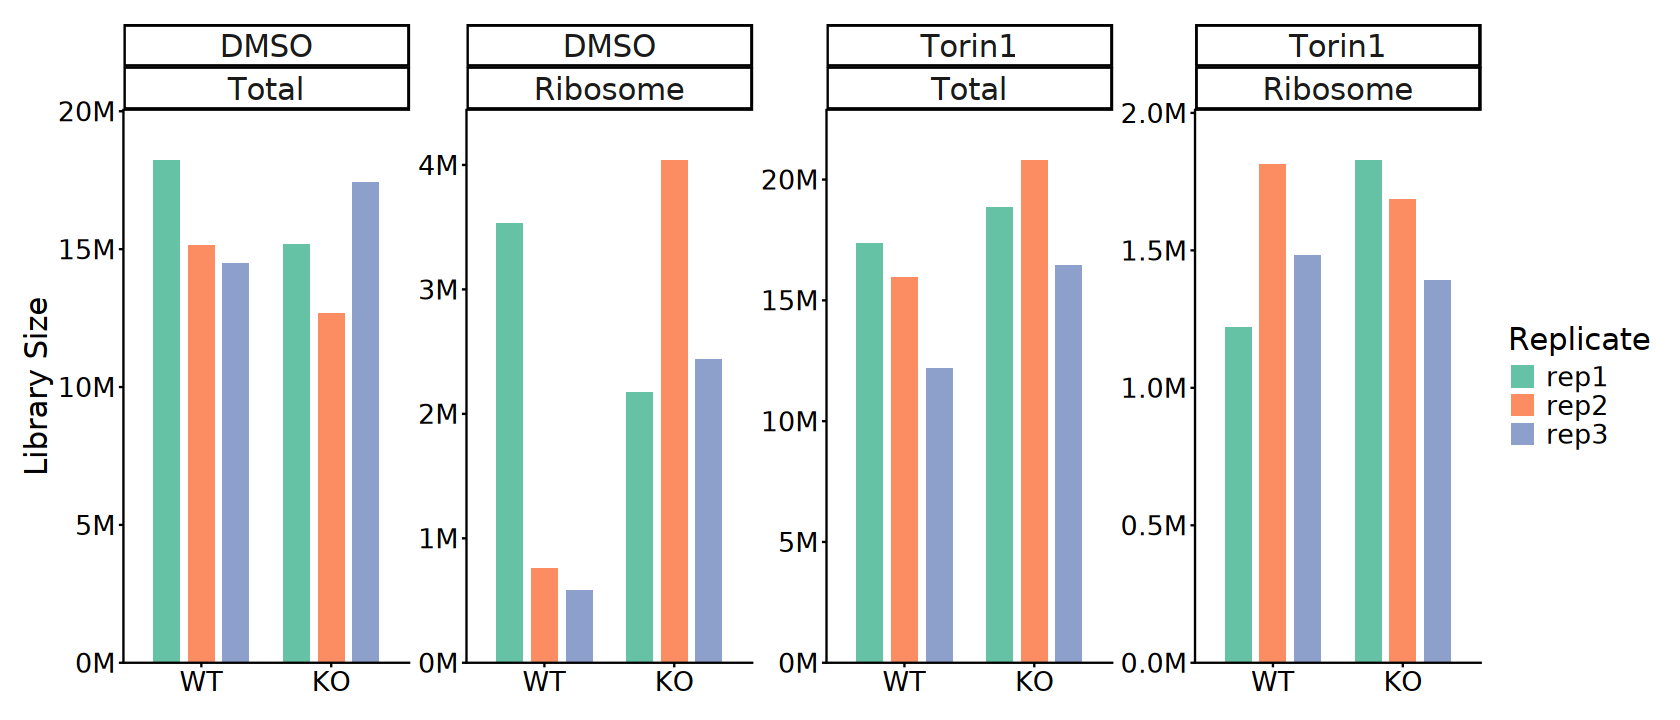

In [25]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(Treatment ~ Fraction, nrow = 1, scales = "free_y") +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [26]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [27]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [28]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Treatment), size = 5) +
    facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [29]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Treatment", "Fraction", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [30]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Treatment), size = 5) +
    facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [31]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [32]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Treatment), size = 5) +
    facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

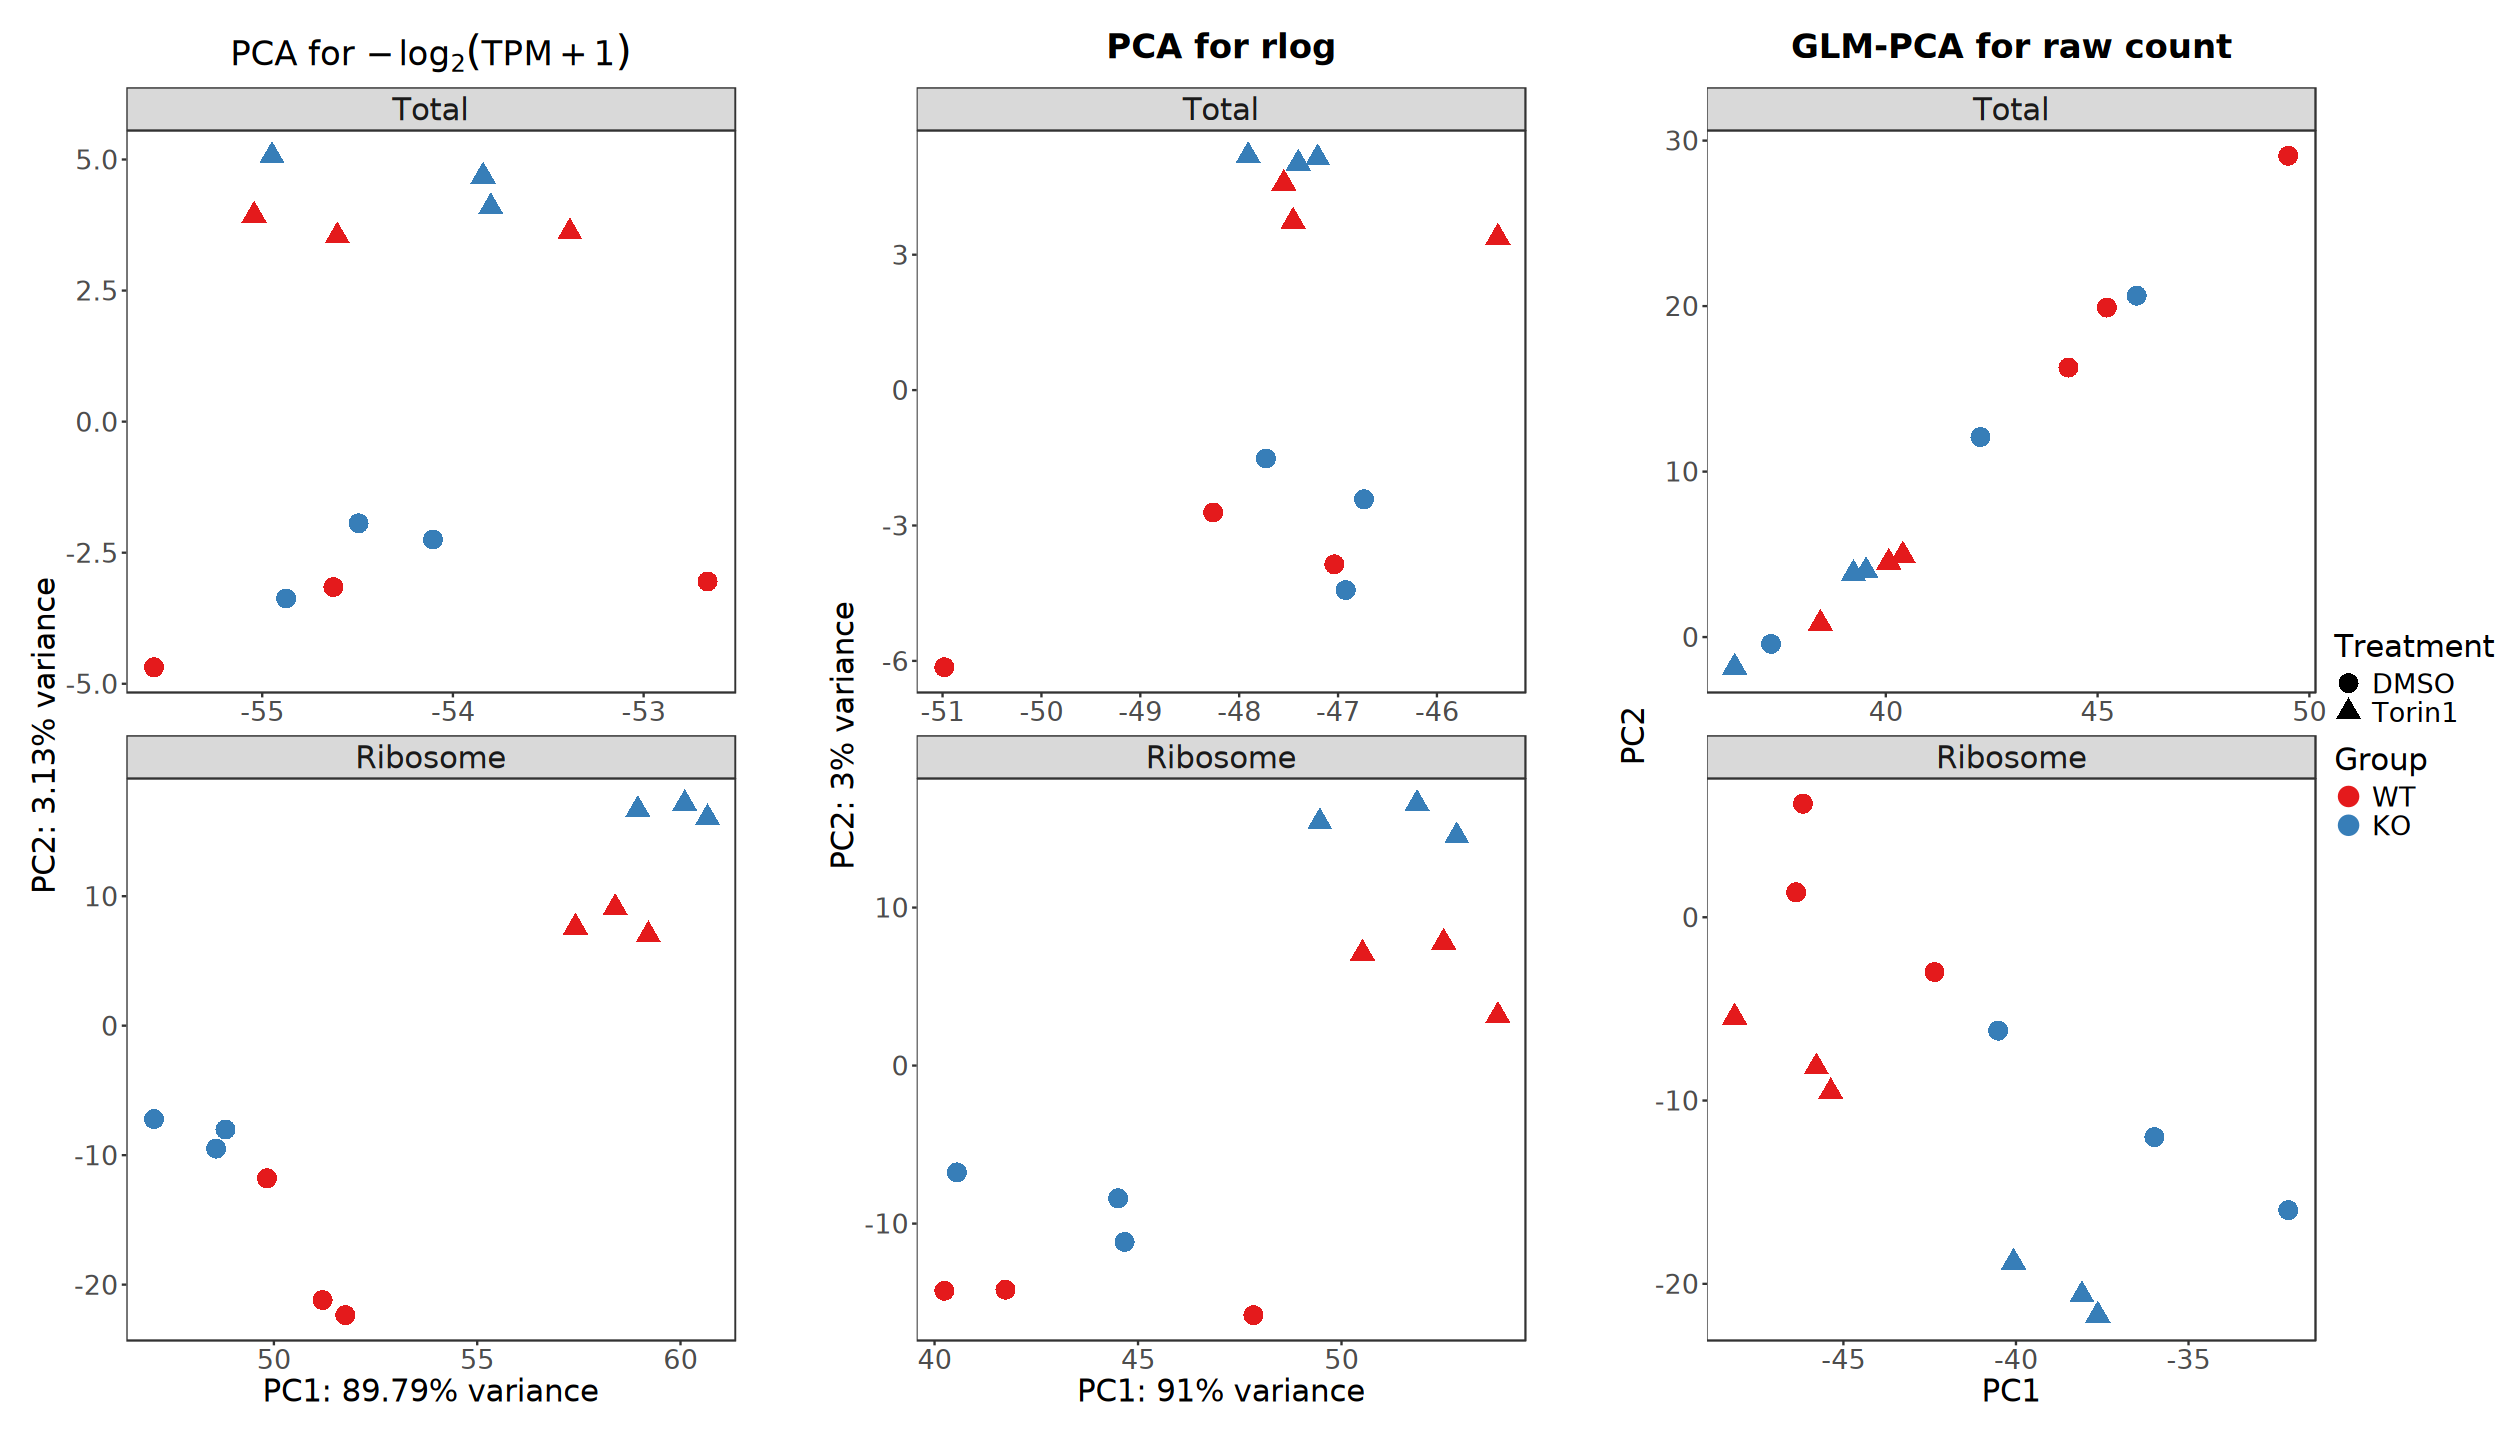

In [33]:
options(repr.plot.width = 21, repr.plot.height = 12)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [34]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

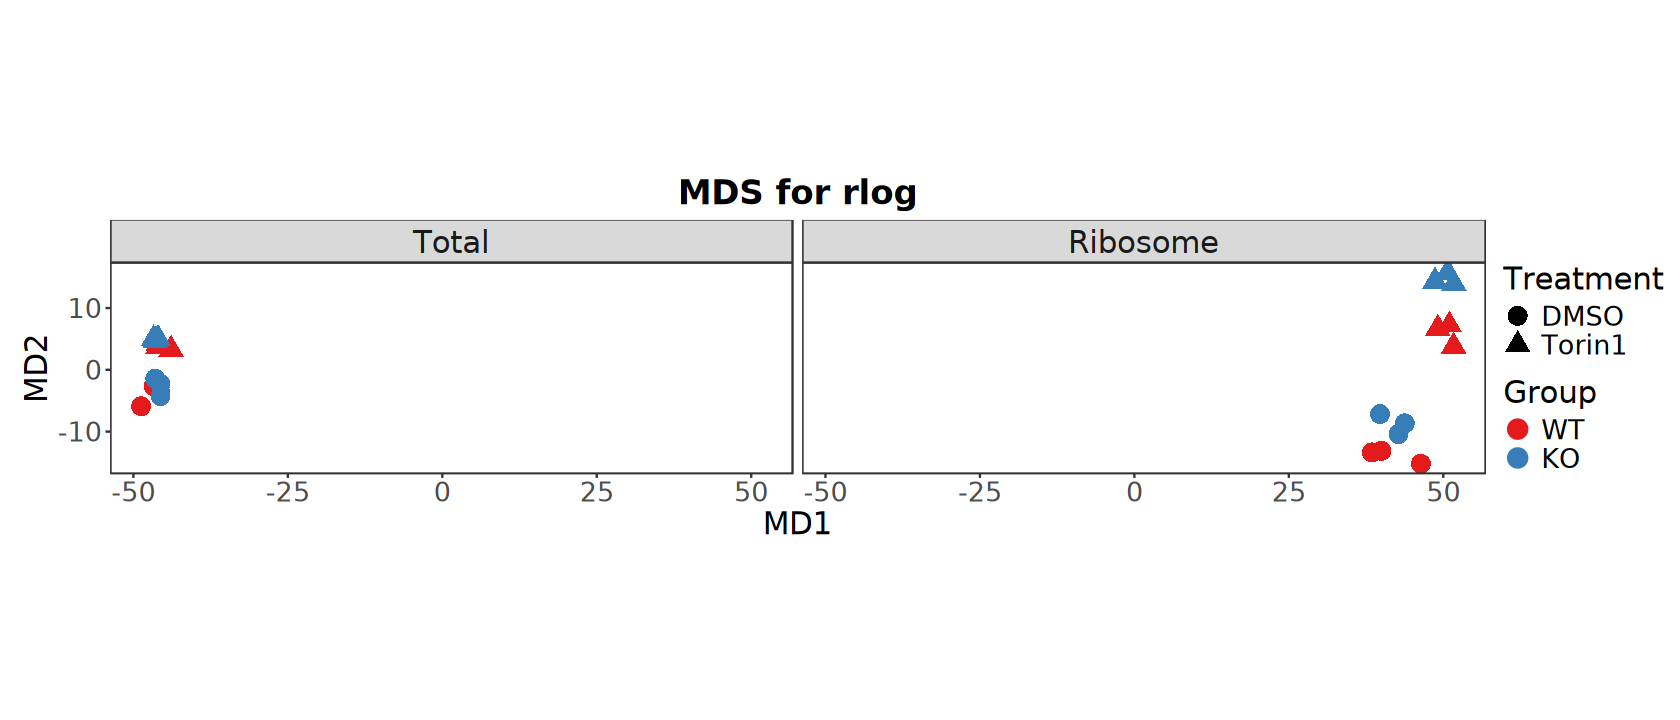

In [35]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Treatment), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [36]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

Warning message in vegan::vegdist(t(norm_vs[top_var_idx, ]), method = "bray"):
“results may be meaningless because data have negative entries
                 in method “bray””


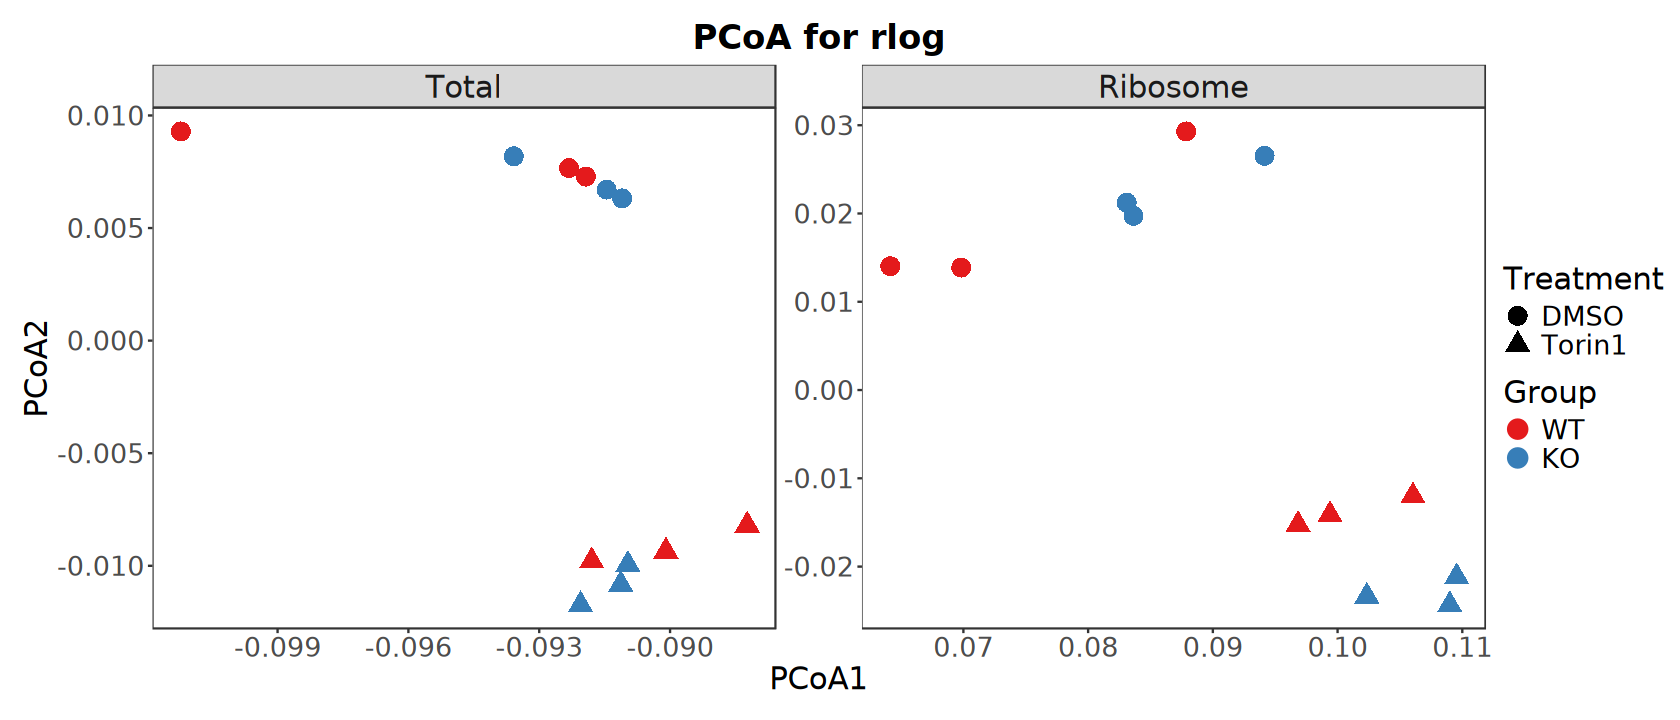

In [37]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Treatment), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [38]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Treatment, Group)

In [39]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
treatment_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Treatment)),
    levels(eSet$Treatment))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Paired")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Treatment = treatment_colors,
    Fraction = fraction_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [40]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

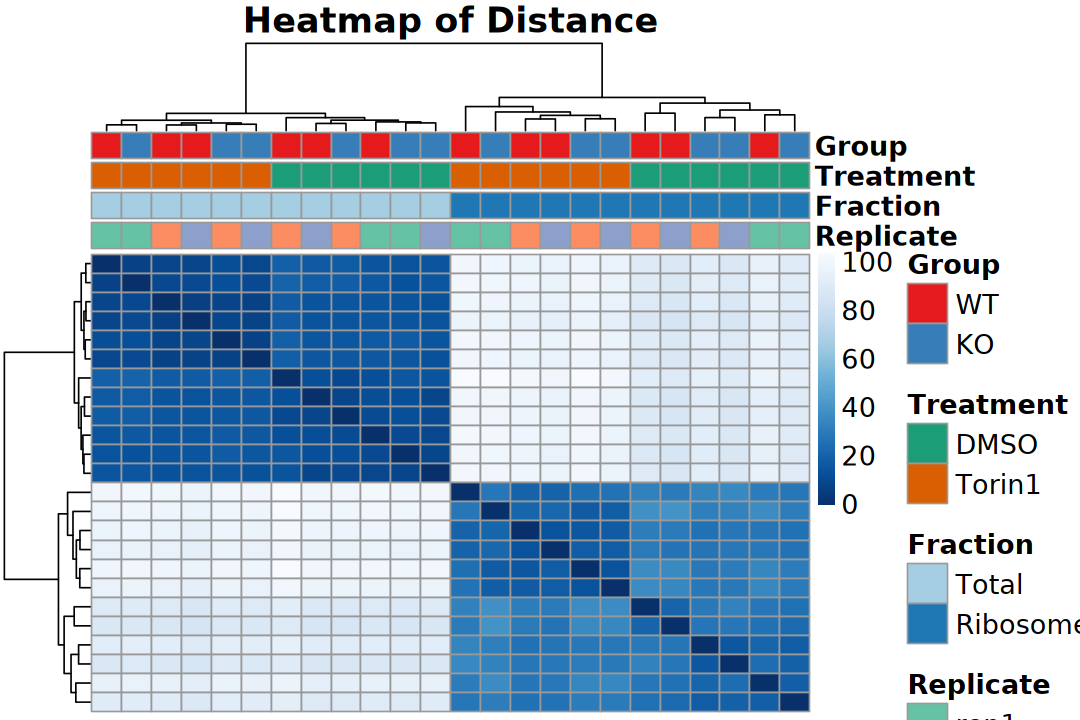

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [42]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

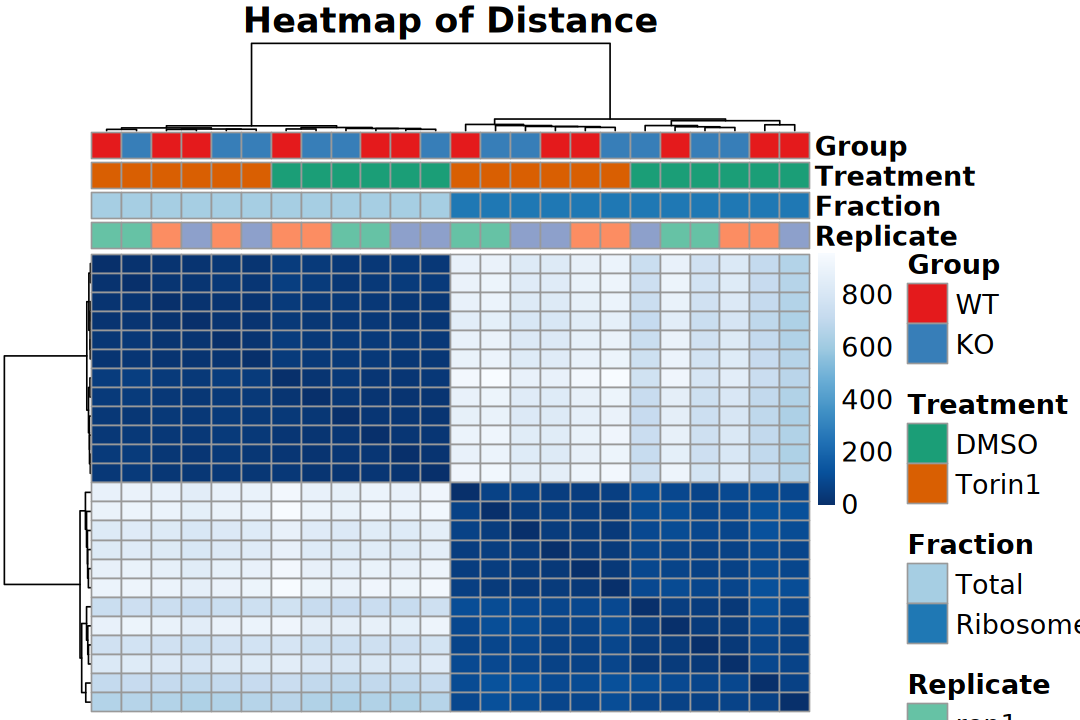

In [43]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [44]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

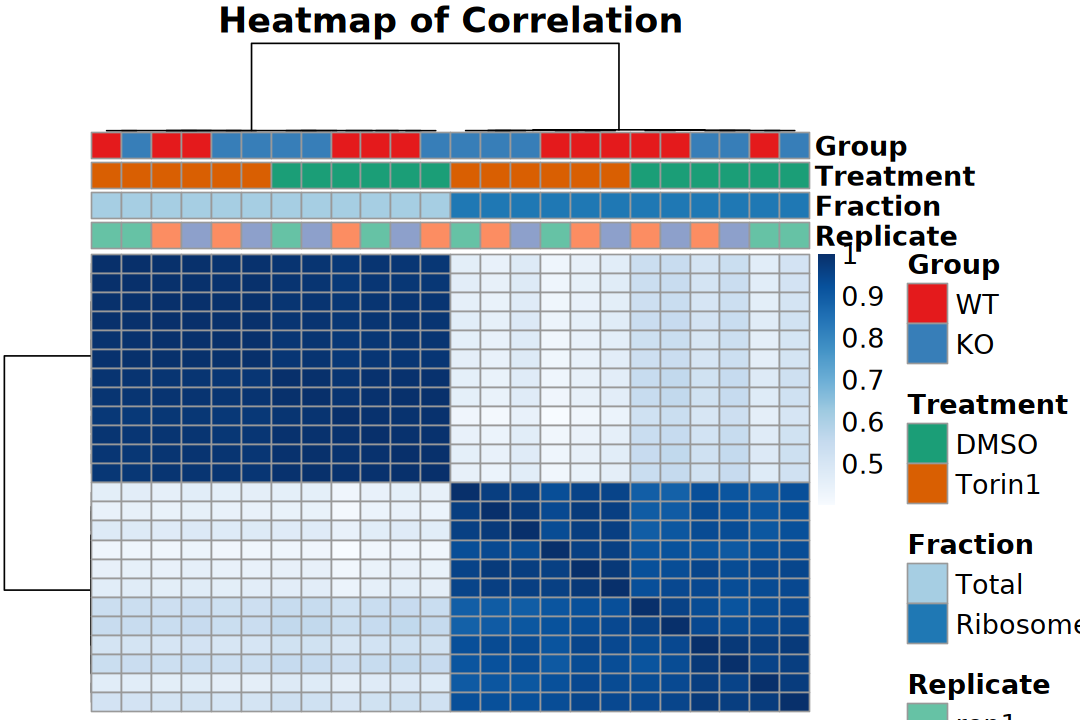

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

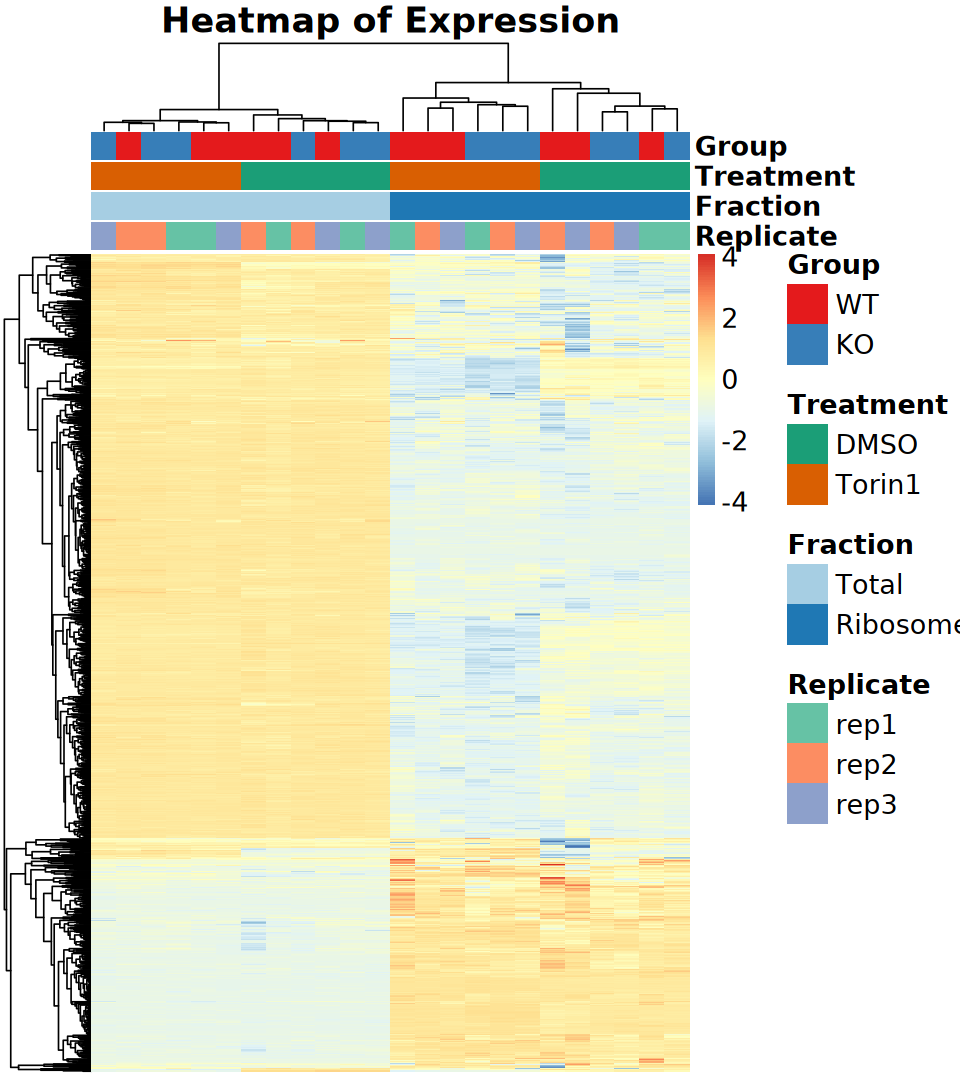

In [46]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. Translation Efficiency

<span style="font-size: 150%">

$$\log_2(\text{TE}) = \log_2\left(\frac{Ribosome\ TPM}{Total\ TPM}\right)$$

$$\log_2(\text{TE}) = \log_2(\text{Ribosome\ TPM}) - \log_2(\text{Total\ TPM})$$

</span>

In [47]:
calculate_log2_te_ext <- function(
    exprmat, coldata, 
    condition_cols = c("Group"), condition_vals = c("Control"), 
    fraction_col = "Fraction", fraction = c("Total", "Ribosome"), 
    replicate_col = "Replicate", replicate = NULL, epsilon = 0) {
    
    # 1. Input validation
    if (length(condition_cols) != length(condition_vals)) {
        stop("Error: 'condition_cols' and 'condition_vals' must have the same length.")
    }

    # 2. Dynamically generate logical index based on arbitrary metadata conditions
    base_filter <- rep(TRUE, nrow(coldata))
    for (i in seq_along(condition_cols)) {
        col_name <- condition_cols[i]
        val <- condition_vals[i]
        
        # Handle NA values correctly during logical matching
        if (is.na(val)) {
            base_filter <- base_filter & is.na(coldata[[col_name]])
        } else {
            base_filter <- base_filter & 
                (!is.na(coldata[[col_name]]) & 
                coldata[[col_name]] == val)
        }
    }

    # 3. Subset metadata for Total and Ribosome fractions
    total_idx <- base_filter & (coldata[[fraction_col]] == fraction[1])
    ribo_idx  <- base_filter & (coldata[[fraction_col]] == fraction[2])
    
    total_info <- coldata[total_idx, , drop = FALSE]
    ribo_info  <- coldata[ribo_idx, , drop = FALSE]
    
    # 4. Handle biological replicates matching
    if (!is.null(replicate)) {
        if (is.numeric(replicate) && length(replicate) == 1) {
            sample_rep_vals <- as.character(coldata[[replicate_col]])
            replicate_ids <- if (any(grepl("rep", sample_rep_vals))) {
                paste0("rep", 1:replicate)
            } else {
                as.character(1:replicate)
            }
        } else {
            replicate_ids <- as.character(replicate)
        }
    
        total_info <- total_info[
            total_info[[replicate_col]] %in% replicate_ids, , drop = FALSE]
        ribo_info  <- ribo_info[
            ribo_info[[replicate_col]] %in% replicate_ids, , drop = FALSE]
        
        # Ensure exact matching order of replicates between Total and Ribosome fractions
        ribo_info  <- ribo_info[
            match(total_info[[replicate_col]], ribo_info[[replicate_col]]), , 
            drop = FALSE]
    }

    # 5. Extract expression matrices and compute log2 Translation Efficiency (TE)
    expr_total <- exprmat[, rownames(total_info), drop = FALSE]
    expr_ribo  <- exprmat[, rownames(ribo_info), drop = FALSE]
    
    log2_te <- log2(expr_ribo + epsilon) - log2(expr_total + epsilon)

    # 6. Construct highly scalable column names automatically
    prefix_vals <- paste(condition_vals, collapse = "_")
    prefix <- paste0("log2TE_", prefix_vals)
    
    if (!is.null(replicate)) {
        colnames(log2_te) <- paste0(
            prefix, "_", total_info[[replicate_col]])
    } else {
        if (nrow(total_info) == 1) {
            colnames(log2_te) <- prefix
        } else {
            colnames(log2_te) <- paste0(
                prefix, "_sample", 1:nrow(total_info))
        }
    }

    # 7. Convert non-finite values (Inf, -Inf, NaN) to NA
    log2_te[!is.finite(log2_te)] <- NA
    
    return(as.matrix(log2_te))
}

In [48]:
te_wt_ctrl  <- calculate_log2_te_ext(
    tpm, colData(eSet), condition_cols = c("Group", "Treatment"), 
    condition_vals = c("WT", "DMSO"), replicate = 3) |>
    rowMeans(na.rm = TRUE)
te_wt_treat <- calculate_log2_te_ext(
    tpm, colData(eSet), condition_cols = c("Group", "Treatment"), 
    condition_vals = c("WT", "Torin1"), replicate = 3) |>
    rowMeans(na.rm = TRUE)
te_ko_ctrl  <- calculate_log2_te_ext(
    tpm, colData(eSet), condition_cols = c("Group", "Treatment"), 
    condition_vals = c("KO", "DMSO"), replicate = 3) |>
    rowMeans(na.rm = TRUE)
te_ko_treat <- calculate_log2_te_ext(
    tpm, colData(eSet), condition_cols = c("Group", "Treatment"), 
    condition_vals = c("KO", "Torin1"), replicate = 3) |>
    rowMeans(na.rm = TRUE)


te_matrix <- cbind(te_wt_ctrl, te_wt_treat, te_ko_ctrl, te_ko_treat)
te_matrix <- cbind(
    te_matrix, delta_te_wt = te_wt_treat - te_wt_ctrl,
    delta_te_ko = te_ko_treat - te_ko_ctrl)

te_df <- te_matrix |> as.data.frame() |>
    rownames_to_column("gene_id") |>
    left_join(
        rowData(eSet) |> as.data.frame() |> 
            dplyr::select(-basepairs) |> 
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id") |>
    mutate(
        delta_te_wt = te_wt_treat - te_wt_ctrl,
        delta_te_ko = te_ko_treat - te_ko_ctrl)

head(te_df)

,te_wt_ctrl,te_wt_treat,te_ko_ctrl,te_ko_treat,delta_te_wt,delta_te_ko,symbol,type
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
ENSMUSG00000051951.5,-0.04915894,-0.87261037,0.84552015,-1.6467937,-0.82345143,-2.4923138,Xkr4,protein_coding
ENSMUSG00000033845.13,-1.01504535,-1.10424881,-0.50520503,-0.8674460,-0.08920346,-0.3622410,Mrpl15,protein_coding
ENSMUSG00000025903.14,-0.15597992,-0.31557759,0.09864190,-0.4454498,-0.15959767,-0.5440917,Lypla1,protein_coding
ENSMUSG00000033813.15,0.16873015,-0.06867718,0.04243357,-0.5911703,-0.23740733,-0.6336038,Tcea1,protein_coding
ENSMUSG00000033793.12,0.15695384,0.50584797,0.36476528,0.7622086,0.34889412,0.3974434,Atp6v1h,protein_coding
ENSMUSG00000025907.14,-0.33424636,-0.30481497,-0.77848846,-0.3424041,0.02943140,0.4360844,Rb1cc1,protein_coding


In [49]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(te_df$delta_te_wt) | is.infinite(te_df$delta_te_ko)
has_nan_or_na <- is.na(te_df$delta_te_wt) | is.na(te_df$delta_te_ko)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- te_df[rows_with_abnormal, , drop = FALSE]

# 4. Output results to the console
if (nrow(abnormal_data) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(head(abnormal_data, 10))
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}

# Keep only rows that do not contain any abnormal values
# te_df <- te_df[!rows_with_abnormal, , drop = FALSE]

                      te_wt_ctrl te_wt_treat te_ko_ctrl te_ko_treat delta_te_wt
ENSMUSG00000025911.14  1.1124144  -0.5482901 -2.3325113         NaN  -1.6607045
ENSMUSG00000025932.14  1.1280536         NaN -1.4803560   0.3360985         NaN
ENSMUSG00000091844.2         NaN  -0.1776804 -1.1101189  -0.7346327         NaN
ENSMUSG00000025993.10        NaN  -1.6543733        NaN         NaN         NaN
ENSMUSG00000006546.3   0.9056612         NaN -2.6950814         NaN         NaN
ENSMUSG00000026200.13        NaN  -0.5754566 -0.6665435  -0.7548504         NaN
ENSMUSG00000032968.4         NaN         NaN -1.8192774  -1.2983388         NaN
ENSMUSG00000022591.5         NaN  -2.8953814        NaN         NaN         NaN
ENSMUSG00000079429.9         NaN  -3.1018323 -3.8541927  -3.5449124         NaN
ENSMUSG00000026354.8   0.2678191   0.8839750 -0.3216976         NaN   0.6161559
                      delta_te_ko  symbol           type
ENSMUSG00000025911.14         NaN  Adhfe1 protein_coding
ENSMUS

# 6. DTEGs

In [50]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

<span style="font-size: 150%">

$$\log_2\text{FC} = \log_2\left( \frac{\text{Ribosome}_{\text{treat}}}{\text{Total}_{\text{treat}}} \right) - \log_2\left( \frac{\text{Ribosome}_{\text{ctrl}}}{\text{Total}_{\text{ctrl}}} \right)$$

</span>

In [51]:
design(dds)

~Group * Treatment * Fraction

In [52]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [53]:
resultsNames(dds)

[1] "Intercept"                               
[2] "Group_KO_vs_WT"                          
[3] "Treatment_Torin1_vs_DMSO"                
[4] "Fraction_Ribosome_vs_Total"              
[5] "GroupKO.TreatmentTorin1"                 
[6] "GroupKO.FractionRibosome"                
[7] "TreatmentTorin1.FractionRibosome"        
[8] "GroupKO.TreatmentTorin1.FractionRibosome"

### a). Standard

In [54]:
# Examining whether treatment responses differ between the two cell types
res <- results(
    dds, name = "GroupKO.TreatmentTorin1.FractionRibosome",
    lfcThreshold = logfc_cutoff, alpha = p_cutoff)

summary(res)


out of 12000 with nonzero total read count
adjusted p-value < 0.05
LFC > 0.26 (up)    : 0, 0%
LFC < -0.26 (down) : 0, 0%
outliers [1]       : 1, 0.0083%
low counts [2]     : 0, 0%
(mean count < 0)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [55]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
    0     0 12000 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,6.795581,-2.37897550,1.6257226,-1.4633342,0.1486045,0.9996182,NS,Xkr4,protein_coding,1941
ENSMUSG00000033845.13,1151.507225,-0.27044892,0.2868791,-0.9427280,0.5211606,0.9996182,NS,Mrpl15,protein_coding,1025
ENSMUSG00000025903.14,149.218729,-0.36147389,0.4112460,-0.8789724,0.4698444,0.9996182,NS,Lypla1,protein_coding,747
ENSMUSG00000033813.15,155.687737,-0.54506363,0.3511384,-1.5522758,0.2216193,0.9996182,NS,Tcea1,protein_coding,999
ENSMUSG00000033793.12,1366.105180,-0.02913854,0.2356632,-0.1236448,0.9470498,0.9996182,NS,Atp6v1h,protein_coding,1449
ENSMUSG00000025907.14,340.481888,0.34332314,0.3906955,0.8787486,0.4789216,0.9996182,NS,Rb1cc1,protein_coding,4764


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [56]:
# Examining whether treatment responses differ between the two cell types
res_lfc <- lfcShrink(
    dds, coef = "GroupKO.TreatmentTorin1.FractionRibosome", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 12000 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 3, 0.025%
LFC < 0 (down)     : 27, 0.22%
outliers [1]       : 1, 0.0083%
low counts [2]     : 4886, 41%
(mean count < 114)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [57]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
    2    20 11978 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,6.795581,-0.01449907,0.1226421,0.1433760,NA,NS,Xkr4,protein_coding,1941
ENSMUSG00000033845.13,1151.507225,-0.04416467,0.1215524,0.3458201,0.8213886,NS,Mrpl15,protein_coding,1025
ENSMUSG00000025903.14,149.218729,-0.03093603,0.1219563,0.3794162,0.8389359,NS,Lypla1,protein_coding,747
ENSMUSG00000033813.15,155.687737,-0.06589739,0.1387752,0.1205962,0.6697134,NS,Tcea1,protein_coding,999
ENSMUSG00000033793.12,1366.105180,-0.01504236,0.1091625,0.9015965,0.9832152,NS,Atp6v1h,protein_coding,1449
ENSMUSG00000025907.14,340.481888,0.03117145,0.1215350,0.3795376,0.8389359,NS,Rb1cc1,protein_coding,4764


In [58]:
comparison_df <- deseq2_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, result_raw = result) |> 
    inner_join(
        deseq2_lfc_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, result_lfc = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    Raw = comparison_df$result_raw, 
    LFC_Shrink = comparison_df$result_lfc))


      LFC_Shrink
Raw       Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       2    20 11978


## 2). edgeR

> Trimmed Mean of M-values (TMM)

### a). Negative binomial GLM framework

In [59]:
design <- model.matrix(~ Group * Treatment * Fraction, data = dgel$samples)
colnames(design)

[1] "(Intercept)"                             
[2] "GroupKO"                                 
[3] "TreatmentTorin1"                         
[4] "FractionRibosome"                        
[5] "GroupKO:TreatmentTorin1"                 
[6] "GroupKO:FractionRibosome"                
[7] "TreatmentTorin1:FractionRibosome"        
[8] "GroupKO:TreatmentTorin1:FractionRibosome"

In [60]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [61]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = "GroupKO:TreatmentTorin1:FractionRibosome")

In [62]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
    1    13 11959 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000024308.15,Tapbp,protein_coding,1442,-1.506330,6.152959,22.33968,2.284375e-06,0.01581763,Down
ENSMUSG00000025857.10,Dnaaf5,protein_coding,2559,-1.290895,6.430671,20.87290,4.907901e-06,0.01581763,Down
ENSMUSG00000030835.6,Nomo1,protein_coding,3642,-1.110271,8.566026,20.46975,6.058122e-06,0.01581763,Down
ENSMUSG00000031156.18,Slc35a2,protein_coding,1484,-1.499637,4.931406,20.09946,7.351741e-06,0.01581763,Down
ENSMUSG00000061666.6,Gdpd1,protein_coding,942,-1.248793,5.566426,19.92925,8.036140e-06,0.01581763,Down
ENSMUSG00000040010.10,Slc7a5,protein_coding,1536,-1.106422,9.767666,19.68183,9.146707e-06,0.01581763,Down


### b). Quasi-likelihood pipeline (edgeR v3)

In [63]:
design <- model.matrix(~ Group * Treatment * Fraction, data = dgel$samples)

In [64]:
dgel_nbglm <- estimateDisp(dgel, design)

In [65]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = "GroupKO:TreatmentTorin1:FractionRibosome")

In [66]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
    0     0 11973 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000030835.6,Nomo1,protein_coding,3642,-1.108947,8.566026,24.55797,2.996405e-05,0.113668,NS
ENSMUSG00000031156.18,Slc35a2,protein_coding,1484,-1.500628,4.931406,23.82621,3.680230e-05,0.113668,NS
ENSMUSG00000040010.10,Slc7a5,protein_coding,1536,-1.106199,9.767666,23.42704,4.119097e-05,0.113668,NS
ENSMUSG00000025857.10,Dnaaf5,protein_coding,2559,-1.304458,6.430671,22.19575,5.876162e-05,0.113668,NS
ENSMUSG00000071650.6,Ganab,protein_coding,2898,-1.075199,9.216686,22.15667,5.942538e-05,0.113668,NS
ENSMUSG00000024308.15,Tapbp,protein_coding,1442,-1.503546,6.152959,22.01632,6.192853e-05,0.113668,NS


In [67]:
comparison_df <- edger_glm_lrt_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, glm_lrt = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, glm_qlf = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    glm_lrt = comparison_df$glm_lrt, 
    glm_qlf = comparison_df$glm_qlf))


       glm_qlf
glm_lrt    Up  Down    NS
   Up       0     0     1
   Down     0     0    13
   NS       0     0 11959


## 3). limma-voom

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [68]:
design <- model.matrix(~ Group * Treatment * Fraction, data = dgel$samples)

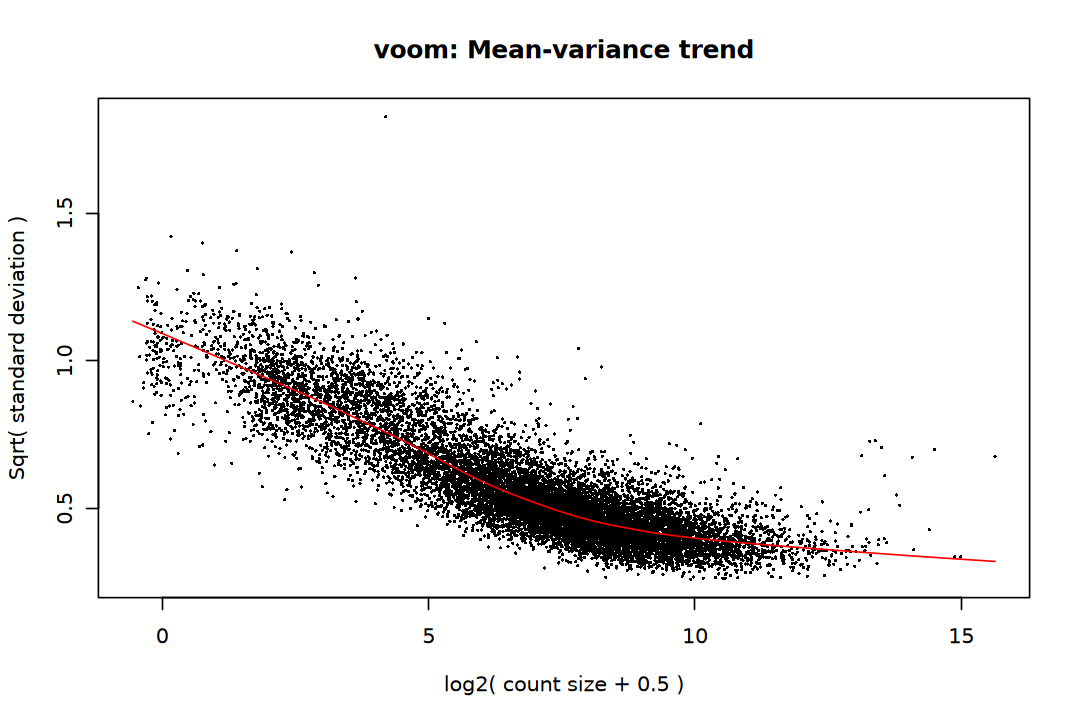

In [69]:
options(repr.plot.width = 9, repr.plot.height = 6)
norm_v <- voom(dgel, design, plot = TRUE)

In [70]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [71]:
limma_voom_result <- topTable(
    efit, coef = "GroupKO:TreatmentTorin1:FractionRibosome", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
    0     0 11973 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000071650.6,Ganab,protein_coding,2898,-1.0631412,9.124799,-5.086485,2.520862e-05,0.1433922,2.597525,NS
ENSMUSG00000040010.10,Slc7a5,protein_coding,1536,-1.0747786,9.548335,-4.950216,3.625182e-05,0.1433922,2.243696,NS
ENSMUSG00000030835.6,Nomo1,protein_coding,3642,-1.1222882,8.321816,-4.888240,4.276916e-05,0.1433922,2.145937,NS
ENSMUSG00000025534.17,Gusb,protein_coding,1973,-1.0303219,7.595731,-4.654550,7.977939e-05,0.1652097,1.567477,NS
ENSMUSG00000027195.10,Hsd17b12,protein_coding,936,-0.7285789,8.150466,-4.582834,9.658964e-05,0.1652097,1.346817,NS
ENSMUSG00000030110.13,Ret,protein_coding,3374,-0.7032592,10.058714,-4.599008,9.251382e-05,0.1652097,1.323706,NS


In [72]:
comparison_df <- limma_voom_result |> 
    rownames_to_column("gene_id") |>
    dplyr::select(gene_id, limma = result) |> 
    inner_join(
        edger_glm_qlf_result |> 
            rownames_to_column("gene_id") |>
            dplyr::select(gene_id, edger = result),
        by = c("gene_id"))

cat("\n=========================================\n")
print(table(
    limma = comparison_df$limma, 
    edger = comparison_df$edger))


      edger
limma     Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 11973


## DEGs Evaluation

In [73]:
add_label <- function(res, symbol_col = "symbol", type_col = "type") {
    res |> rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            valid = .data[[type_col]] == "protein_coding" & 
                result %in% c("Up", "Down"),
            label = dplyr::if_else(
                valid & cumsum(valid) <= 5, 
                .data[[symbol_col]], NA_character_)
        ) |>
        dplyr::ungroup() |>
        column_to_rownames("gene_id")
}

In [74]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_lrt_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [75]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [76]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

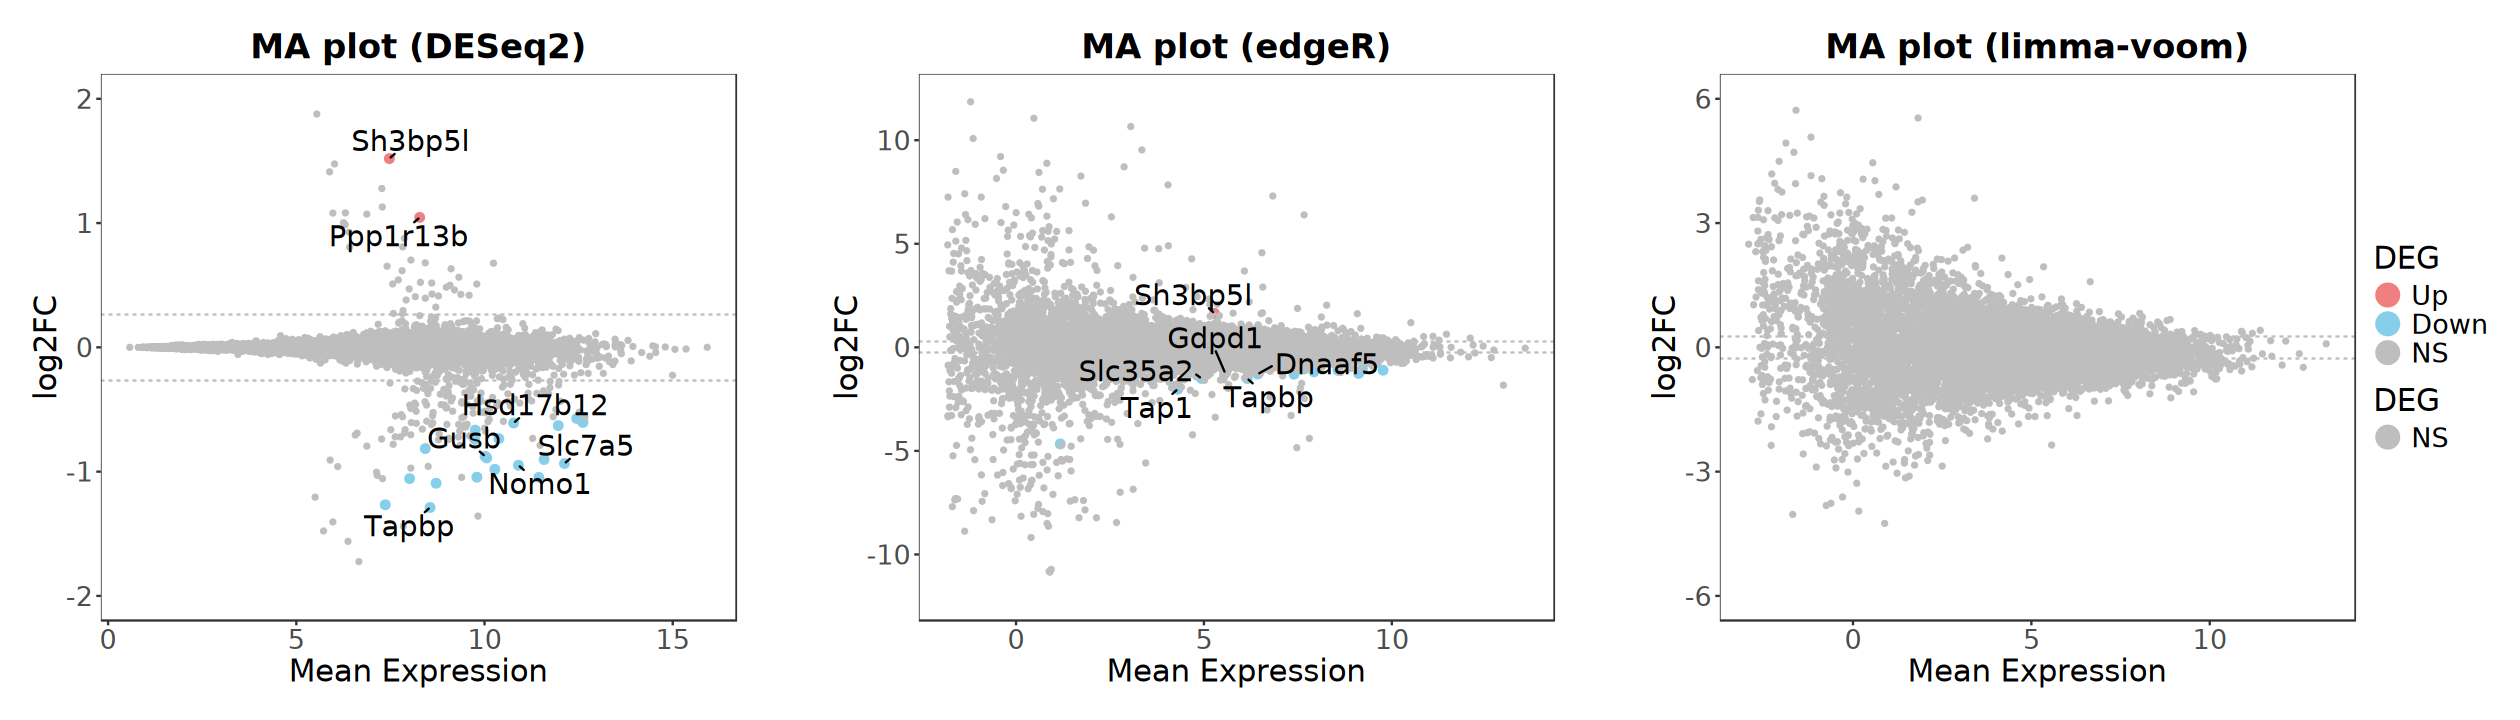

In [77]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [78]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 1) * 1)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [79]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_hline()`).”


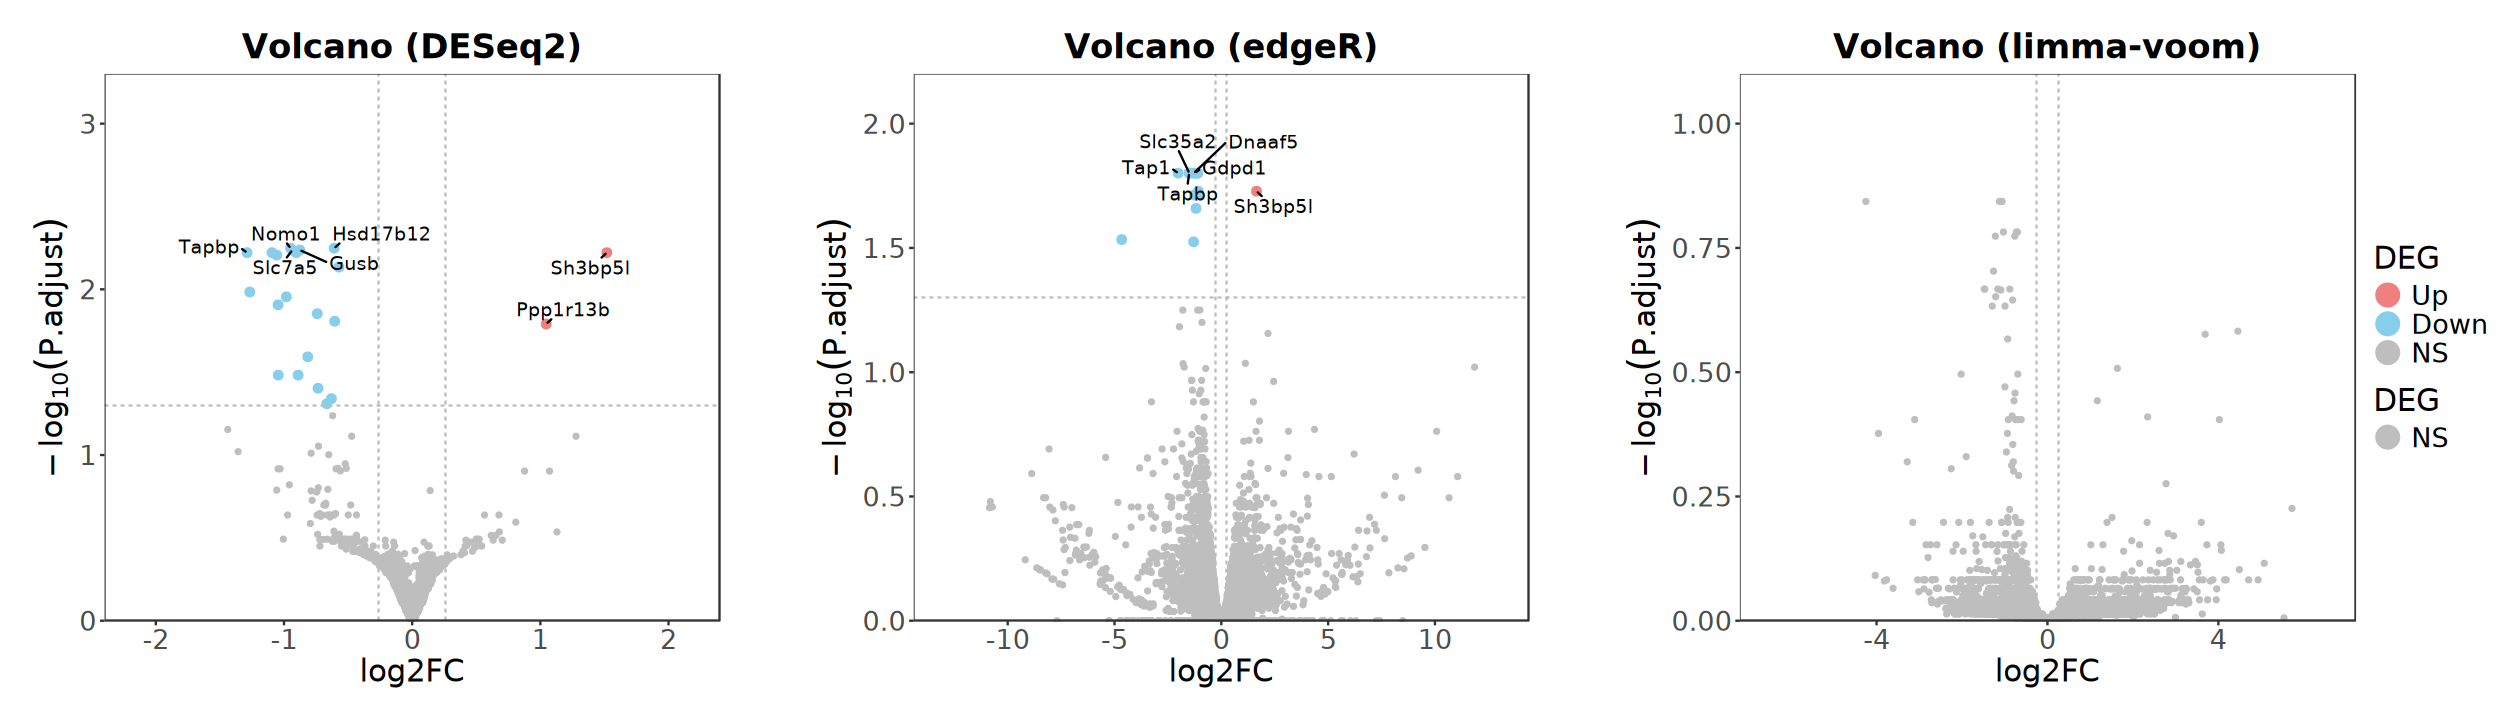

In [80]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [81]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [82]:
genes_up <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Up", "symbol"], 
    edgeR = edger_result[edger_result$result == "Up", "symbol"], 
    limma = limma_result[limma_result$result == "Up", "symbol"])
genes_up <- lapply(genes_up, unique)

In [83]:
genes_down <- list(
    DESeq2 = deseq2_result[deseq2_result$result == "Down", "symbol"], 
    edgeR = edger_result[edger_result$result == "Down", "symbol"], 
    limma = limma_result[limma_result$result == "Down", "symbol"])
genes_down <- lapply(genes_down, unique)

In [84]:
p1 <- ggVennDiagram(genes_up, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(genes_down, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

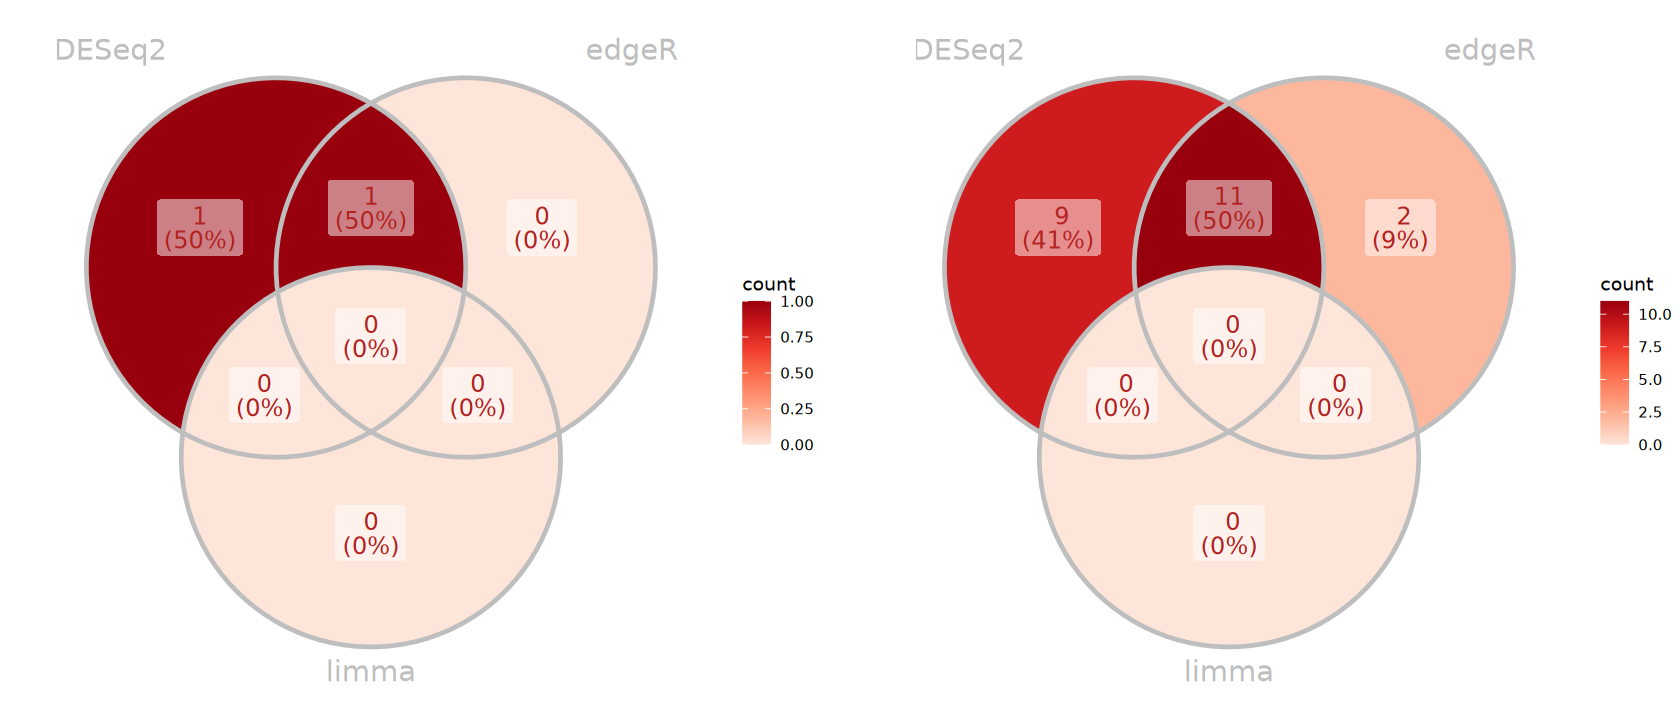

In [85]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Visualization

In [86]:
degs_result <- left_join(
    deseq2_result |> rownames_to_column("gene_id"), 
    te_matrix |> as.data.frame() |> rownames_to_column("gene_id"), 
    by = "gene_id") |>
    column_to_rownames("gene_id")

head(degs_result)

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,valid,label,te_wt_ctrl,te_wt_treat,te_ko_ctrl,te_ko_treat,delta_te_wt,delta_te_ko
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<lgl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ENSMUSG00000013646.17,176.5110,1.5186668,0.4038263,6.754182e-06,0.006005312,Up,Sh3bp5l,protein_coding,1176,TRUE,Sh3bp5l,-1.5207388,-1.9178232,-2.31809810,-0.8126844,-0.3970844,1.50541374
ENSMUSG00000021285.15,309.3375,1.0457795,0.3098911,3.642605e-05,0.016193656,Up,Ppp1r13b,protein_coding,3366,TRUE,Ppp1r13b,-0.2967933,-1.5054845,-1.09490165,-1.0848336,-1.2086912,0.01006801
ENSMUSG00000030835.6,1911.6792,-0.9487009,0.2291012,1.588377e-06,0.005649064,Down,Nomo1,protein_coding,3642,TRUE,Nomo1,-0.3151231,-1.8463367,-0.20827345,-2.7096918,-1.5312137,-2.50141834
ENSMUSG00000027195.10,1749.8164,-0.6087732,0.1444562,1.466239e-06,0.005649064,Down,Hsd17b12,protein_coding,936,TRUE,Hsd17b12,1.4705283,1.3679469,1.73530946,1.0323115,-0.1025815,-0.70299794
ENSMUSG00000040010.10,4462.4933,-0.9351128,0.2352864,3.224386e-06,0.005794111,Down,Slc7a5,protein_coding,1536,TRUE,Slc7a5,0.6147094,-0.3737255,0.62459028,-1.3444599,-0.9884349,-1.96905021
ENSMUSG00000025534.17,1033.0448,-0.8766164,0.2208750,3.258322e-06,0.005794111,Down,Gusb,protein_coding,1973,TRUE,Gusb,-0.1340407,-0.4548083,0.08921753,-1.2046288,-0.3207676,-1.29384638


In [87]:
# 1. Create logical matrices to identify infinite and missing/NaN values
has_inf <- is.infinite(degs_result$delta_te_wt) | is.infinite(degs_result$delta_te_ko)
has_nan_or_na <- is.na(degs_result$delta_te_wt) | is.na(degs_result$delta_te_ko)

# 2. Combine conditions: a row is marked TRUE if it contains any abnormal value
rows_with_abnormal <- has_inf | has_nan_or_na

# 3. Extract rows containing abnormal values
abnormal_data <- degs_result[rows_with_abnormal, , drop = FALSE]

# 4. Output results to the console
if (nrow(abnormal_data) > 0) {
    cat("Warning: Found", nrow(abnormal_data), "row(s) with abnormal values:\n")
    print(head(abnormal_data))
} else {
    cat("Success: No Inf, -Inf, NaN, or NA values detected in the table.\n")
}

print(table(abnormal_data$result))

                       baseMean         logFC     lfcSE      pvalue      padj
ENSMUSG00000114279.1   556.1809  0.0223678778 0.1245394 0.007626244 0.3767047
ENSMUSG00000069274.3  1016.3605 -0.0141417001 0.1228315 0.026760417 0.4855787
ENSMUSG00000064288.4   617.8090 -0.0145625799 0.1227674 0.085549590 0.6292805
ENSMUSG00000045350.15  910.7206  0.0006524956 0.1217401 0.088618182 0.6342460
ENSMUSG00000100210.2   903.4846 -0.0126785700 0.1225243 0.092612692 0.6400410
ENSMUSG00000069302.5   584.6515  0.0062619802 0.1219002 0.211271176 0.7601237
                      result    symbol           type basepairs valid label
ENSMUSG00000114279.1      NS Hist1h2bm protein_coding       378 FALSE  <NA>
ENSMUSG00000069274.3      NS  Hist1h4f protein_coding       309 FALSE  <NA>
ENSMUSG00000064288.4      NS  Hist1h4k protein_coding       309 FALSE  <NA>
ENSMUSG00000045350.15     NS   Fam186a protein_coding      9105 FALSE  <NA>
ENSMUSG00000100210.2      NS  Hist1h3f protein_coding       408 FALSE  <NA


  Up Down   NS 
   0    0  574 


### Scatter Plot

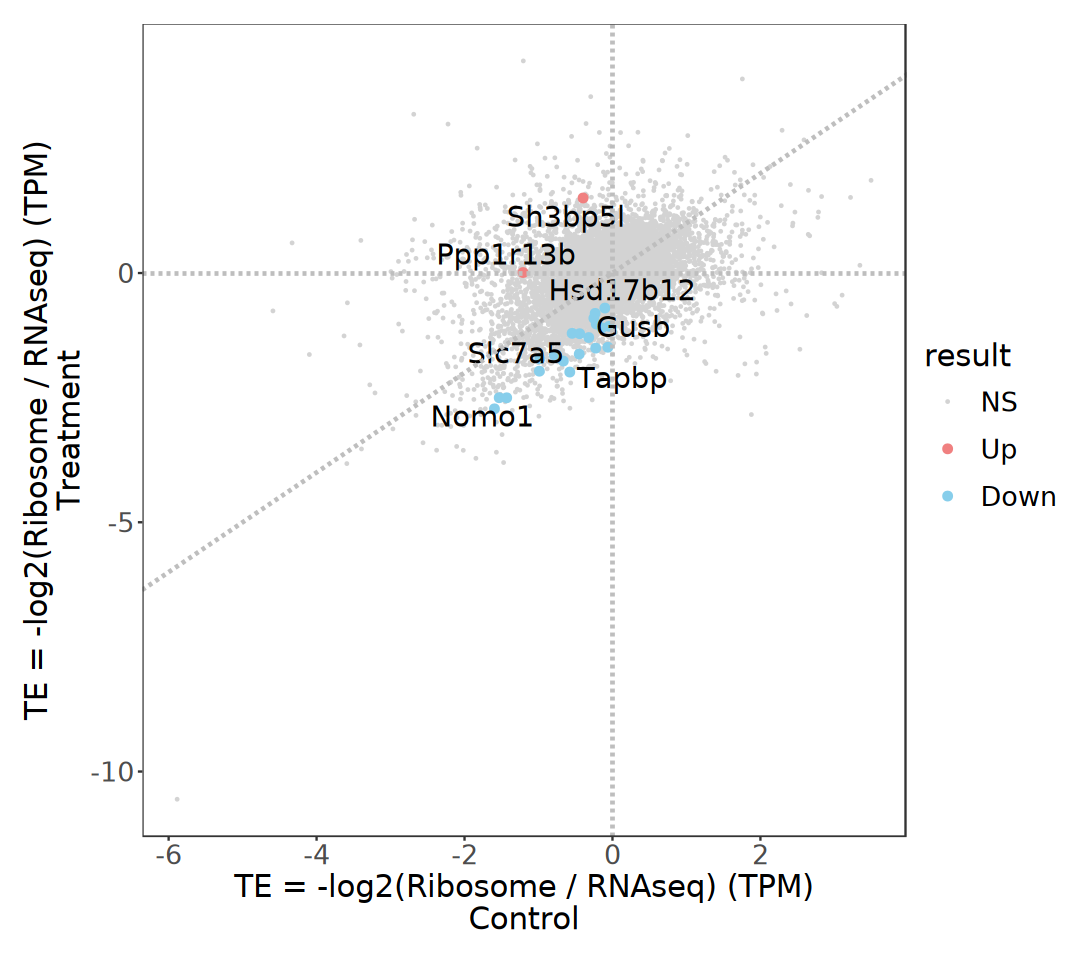

In [88]:
options(repr.plot.width = 9, repr.plot.height = 8)

# axisRange <- c(degs_result$delta_te_wt, degs_result$delta_te_ko) |> 
#     na.omit() %>% .[is.finite(.)] |> abs() |> max(na.rm = T) |> ceiling()

ggplot(degs_result, aes(x = delta_te_wt, y = delta_te_ko)) +
    geom_point(
        data = subset(degs_result, result == "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_point(
        data = subset(degs_result, result != "NS"), 
        aes(color = result, size = result), na.rm = TRUE) + 
    geom_text_repel(
        aes(label = label),  na.rm = TRUE, size = 6, 
        color = "black", max.overlaps = Inf) +
    geom_hline(
        yintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_vline(
        xintercept = 0, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "gray", linewidth = 1) +
    # xlim(-axisRange, axisRange) + 
    # ylim(-axisRange, axisRange) + 
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "LightGray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 0.3))+
    labs(x = "TE = -log2(Ribosome / RNAseq) (TPM)\n Control ", 
         y = "TE = -log2(Ribosome / RNAseq) (TPM)\n Treatment ") + 
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [89]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [90]:
ar <- degs_result |> 
    dplyr::select(DTEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Treatment, Group)

In [91]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
treatment_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Treatment)),
    levels(eSet$Treatment))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Paired")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Treatment = treatment_colors,
    Fraction = fraction_colors, 
    Replicate = replicate_colors, DTEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

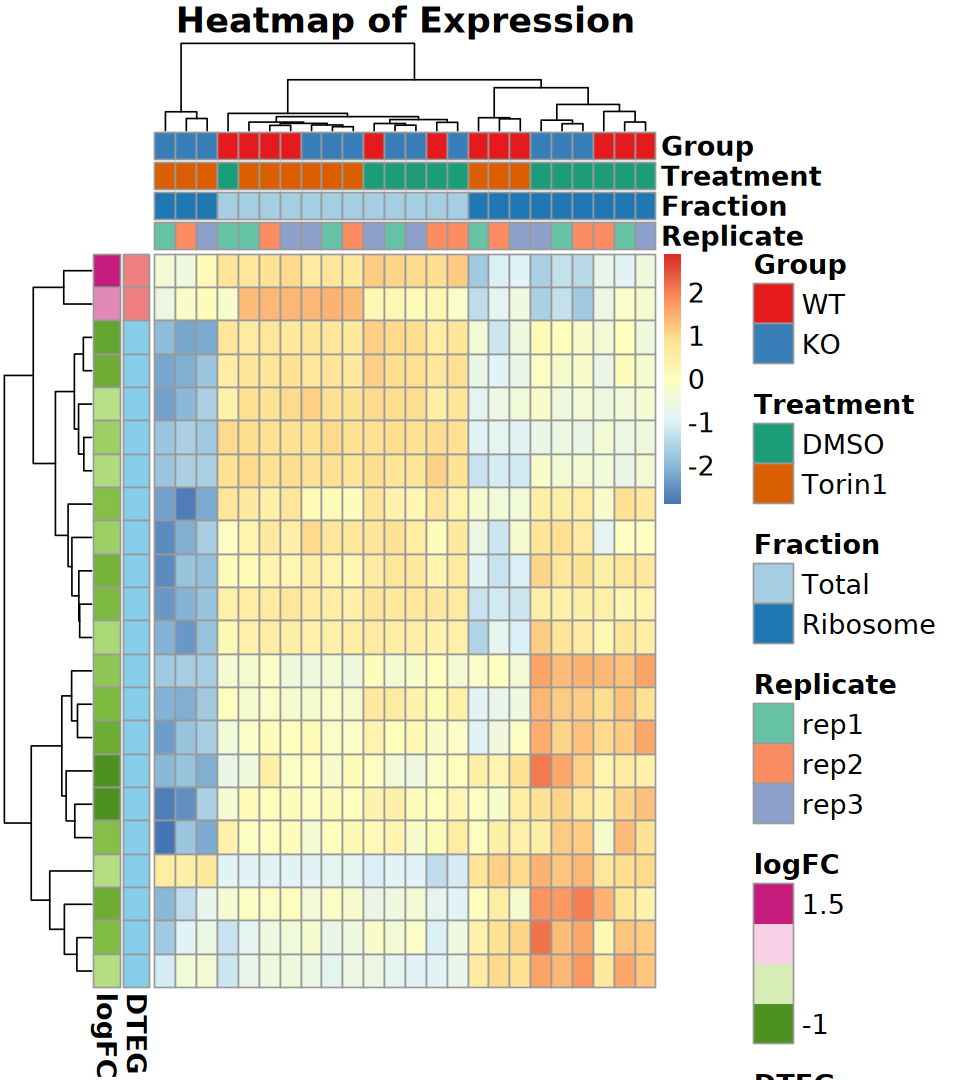

In [92]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [93]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [94]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [95]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
treatment_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Treatment)),
    levels(eSet$Treatment))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Paired")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [96]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Treatment, Fraction, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Treatment = treatment_colors,
        Fraction = fraction_colors,
        Replicate = replicate_colors))

In [97]:
ar <- degs_result |> 
    dplyr::select(logFC, DTEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DTEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [98]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [99]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_treatment <- Legend(
    title = "Treatment", labels = levels(dds$Treatment))
lg_fraction <- Legend(
    title = "Fraction", labels = levels(dds$Fraction))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DTEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_treatment, lg_fraction, lg_replicate) |>
    packLegend(direction = "vertical")

In [100]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

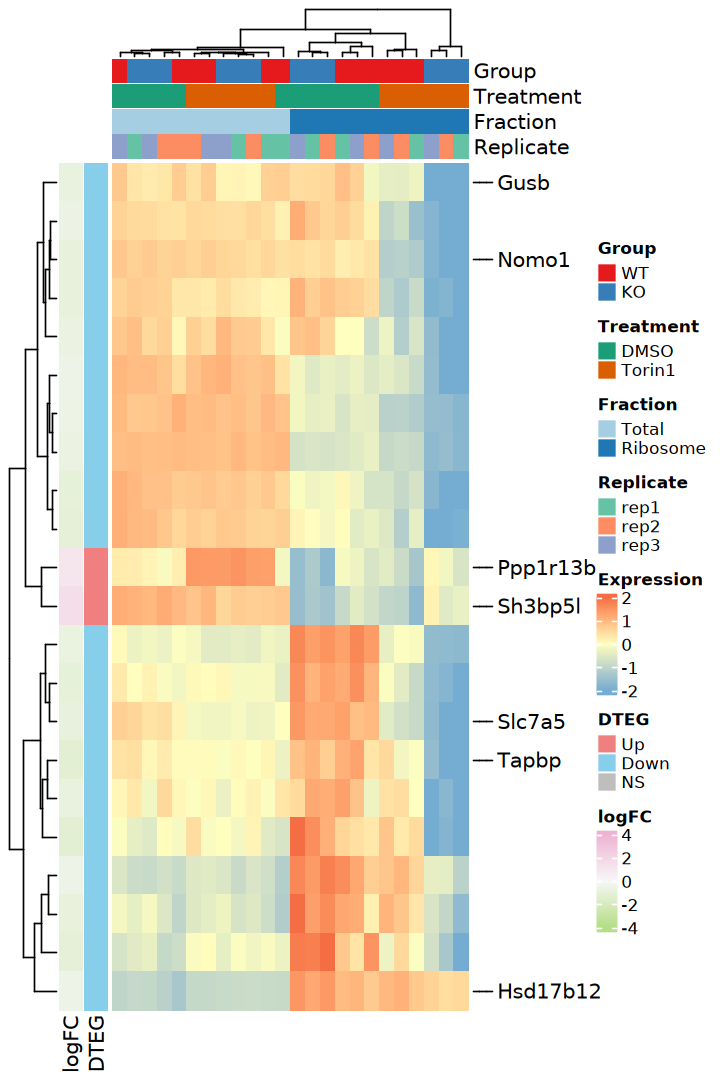

In [101]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

## 4). anota2seq

In [102]:
# suppressPackageStartupMessages(library(anota2seq))

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)